# 01. Data Preparation and Quality Checks

This notebook converts the primary State Statistics Service file into a compact monthly average-price dataset, audits missingness and coverage, flags suspicious month-to-month changes for review, and prepares the national target series. It preserves missing observations and never silently imputes or deletes values.

The source file is large. Run the chunked extraction once; subsequent sections use the processed CSV.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the project root containing data/")
RAW_FILE = ROOT / "data" / "raw" / "136.csv"
PROCESSED_FILE = ROOT / "data" / "processed" / "avg_prices_monthly.csv"
if not RAW_FILE.exists():
    raise FileNotFoundError(f"Source data not found: {RAW_FILE}")
USECOLS = [0, 4, 5, 6, 7, 8, 10, 11, 13, 21]
NAMES = ["indicator", "region_code", "region", "good_code", "good",
         "freq", "period", "value", "unit", "obs_note"]
UKRAINE = "\u0423\u043a\u0440\u0430\u0457\u043d\u0430"
TARGET_GOODS = {
    "Potato": "\u041a\u0430\u0440\u0442\u043e\u043f\u043b\u044f",
    "Carrot": "\u041c\u043e\u0440\u043a\u0432\u0430",
    "Eggs": "\u042f\u0439\u0446\u044f",
    "Pasteurized milk": "\u041c\u043e\u043b\u043e\u043a\u043e \u043f\u0430\u0441\u0442\u0435\u0440\u0438\u0437\u043e\u0432\u0430\u043d\u0435 \u0436\u0438\u0440\u043d\u0456\u0441\u0442\u044e \u0434\u043e 2,6% \u0432\u043a\u043b\u044e\u0447\u043d\u043e",
    "A-95 gasoline": "\u0411\u0435\u043d\u0437\u0438\u043d \u0410-95",
    "Sunflower oil": "\u041e\u043b\u0456\u044f \u0441\u043e\u043d\u044f\u0448\u043d\u0438\u043a\u043e\u0432\u0430",
}

## 1. Extract Monthly Average Consumer Prices

Keep only `AVG_CONS_PRCS` at monthly frequency (`M`). Parse the observation value as numeric and the `YYYY-Mmm` period as a month-start timestamp. The original source row count and retained row count are reported. Do not overwrite or alter `data/raw/136.csv`.

In [2]:
chunks = []
total_rows = 0
reader = pd.read_csv(
    RAW_FILE, header=0, names=NAMES, usecols=USECOLS, dtype=str,
    encoding="utf-8-sig", chunksize=100_000,
)
for chunk in reader:
    total_rows += len(chunk)
    selected = chunk[(chunk["indicator"] == "AVG_CONS_PRCS") & (chunk["freq"] == "M")].copy()
    if not selected.empty:
        chunks.append(selected)
if not chunks:
    raise ValueError("No monthly AVG_CONS_PRCS records were found")
p = pd.concat(chunks, ignore_index=True)
p["value"] = pd.to_numeric(p["value"], errors="coerce")
p["date"] = pd.to_datetime(p["period"].str.replace("-M", "-", regex=False) + "-01", errors="coerce")
invalid_dates = int(p["date"].isna().sum())
if invalid_dates:
    raise ValueError(f"Could not parse {invalid_dates} monthly period values")
key_cols = ["indicator", "region_code", "good_code", "freq", "period"]
duplicate_rows = int(p.duplicated(key_cols, keep=False).sum())
print(f"Source rows scanned: {total_rows:,}")
print(f"Monthly average-price rows retained: {len(p):,}")
print(f"Duplicate observations by source key: {duplicate_rows:,}")
if duplicate_rows:
    display(p[p.duplicated(key_cols, keep=False)].sort_values(key_cols).head(20))
PROCESSED_FILE.parent.mkdir(parents=True, exist_ok=True)
p.to_csv(PROCESSED_FILE, index=False, encoding="utf-8-sig")
print("Saved processed data to:", PROCESSED_FILE)

Source rows scanned: 374,259
Monthly average-price rows retained: 145,860
Duplicate observations by source key: 0
Saved processed data to: d:\УКУ\4 курс\Прогнози\проєкт\дані\data\processed\avg_prices_monthly.csv


## 2. Dataset Shape, Series Length, and Completeness

The dataset is already monthly; do not aggregate it to a different frequency. Treat `value` as the published average price in the corresponding reported unit. The national row labelled Ukraine is the official aggregate in this source, so use it directly rather than taking an unweighted mean of regional prices.

In [3]:
p = pd.read_csv(PROCESSED_FILE, parse_dates=["date"])
p["is_missing"] = p["value"].isna()
print("Rows:", f"{len(p):,}")
print("Date range:", p["date"].min().date(), "to", p["date"].max().date())
print("Distinct months:", p["date"].nunique())
print("Territorial categories:", p["region"].nunique(), "| Products:", p["good"].nunique())
print("Missing price values:", f"{p['is_missing'].sum():,}", f"({p['is_missing'].mean():.2%})")
series_profile = (p.groupby(["region", "good"], dropna=False)
    .agg(n=("value", "size"), missing=("value", lambda s: s.isna().sum()),
         first_date=("date", "min"), last_date=("date", "max"), unit=("unit", "first"))
    .reset_index())
print("Series length distribution:")
display(series_profile["n"].describe().to_frame("observations_per_region_product"))
print("Series with incomplete observations:")
display(series_profile[series_profile["missing"] > 0].sort_values("missing", ascending=False))

Rows: 145,860
Date range: 2017-01-01 to 2025-06-01
Distinct months: 102
Territorial categories: 26 | Products: 55
Missing price values: 9,001 (6.17%)
Series length distribution:


,observations_per_region_product
count,1430.0
mean,102.0
std,0.0
min,102.0
25%,102.0
50%,102.0
75%,102.0
max,102.0


Series with incomplete observations:


,region,good,n,missing,first_date,last_date,unit
624,Луганська,Крупи пшеничні,102,100,2017-01-01,2025-06-01,Кілограм
629,Луганська,Молочні суміші для дитячого харчування,102,99,2017-01-01,2025-06-01,250 г
239,Донецька,Крупи пшеничні,102,99,2017-01-01,2025-06-01,Кілограм
244,Донецька,Молочні суміші для дитячого харчування,102,98,2017-01-01,2025-06-01,250 г
360,Закарпатська,Проїзд у міському транспорті,102,98,2017-01-01,2025-06-01,Квиток
...,...,...,...,...,...,...,...
1200,Херсонська,Судинорозширювальні засоби імпортні,102,1,2017-01-01,2025-06-01,"10 табл., капсул"
1196,Херсонська,Сири м’які жирні,102,1,2017-01-01,2025-06-01,Кілограм
1198,Херсонська,Стоматологічні послуги,102,1,2017-01-01,2025-06-01,Одиниця
1197,Херсонська,Сметана жирністю до 15% включно,102,1,2017-01-01,2025-06-01,Кілограм


## 3. Missing-Value Reasons and Geographic/Temporal Patterns

Observation notes distinguish values marked **Not observed** from those marked **Not available**. Keep the notes and missing values as-is. The categories describe the source; they do not prove a missing value is a data-entry error. The rise in missing observations in 2022 and subsequent years overlaps a major change in territorial coverage, so apparent regional differences must be interpreted cautiously.

In [4]:
note = p["obs_note"].fillna("")
p["missing_reason"] = np.select(
    [~p["is_missing"], note.str.contains("Not observed", case=False),
     note.str.contains("Not available", case=False)],
    ["Observed", "Not observed", "Not available"],
    default="Missing; reason not classified",
)
print("Missingness reason counts:")
display(p["missing_reason"].value_counts().rename("rows").to_frame())
print("Missing price share by region:")
missing_by_region = (p.groupby("region")["is_missing"].mean()
    .sort_values(ascending=False).rename("missing_share").to_frame())
display(missing_by_region.head(12).style.format("{:.1%}"))
print("Missing prices by calendar year:")
missing_by_year = p.groupby(p["date"].dt.year)["is_missing"].sum().rename("missing_rows")
display(missing_by_year.to_frame())
print("Missing prices by product (all regions):")
display(p.groupby("good")["is_missing"].sum().sort_values(ascending=False).head(15)
        .rename("missing_rows").to_frame())

Missingness reason counts:


,rows
missing_reason,
Observed,136859
Not available,6349
Not observed,2652


Missing price share by region:


,missing_share
region,
Луганська,41.6%
Донецька,40.4%
Харківська,6.8%
Чернігівська,4.8%
Закарпатська,4.6%
Херсонська,4.3%
Одеська,3.2%
Запорізька,2.9%
Волинська,2.9%


Missing prices by calendar year:


,missing_rows
date,
2017,636
2018,636
2019,636
2020,636
2021,612
2022,1748
2023,1631
2024,1642
2025,824


Missing prices by product (all regions):


,missing_rows
good,
Крупи пшеничні,1646
Молочні суміші для дитячого харчування,1620
Сигарети без фільтру,1094
Проїзд у міському транспорті,186
Бензин А-92,116
Хліб пшеничний з борошна першого ґатунку,107
Дошкільна освіта,90
Олія соняшникова,87
Птиця (тушки курячі),87


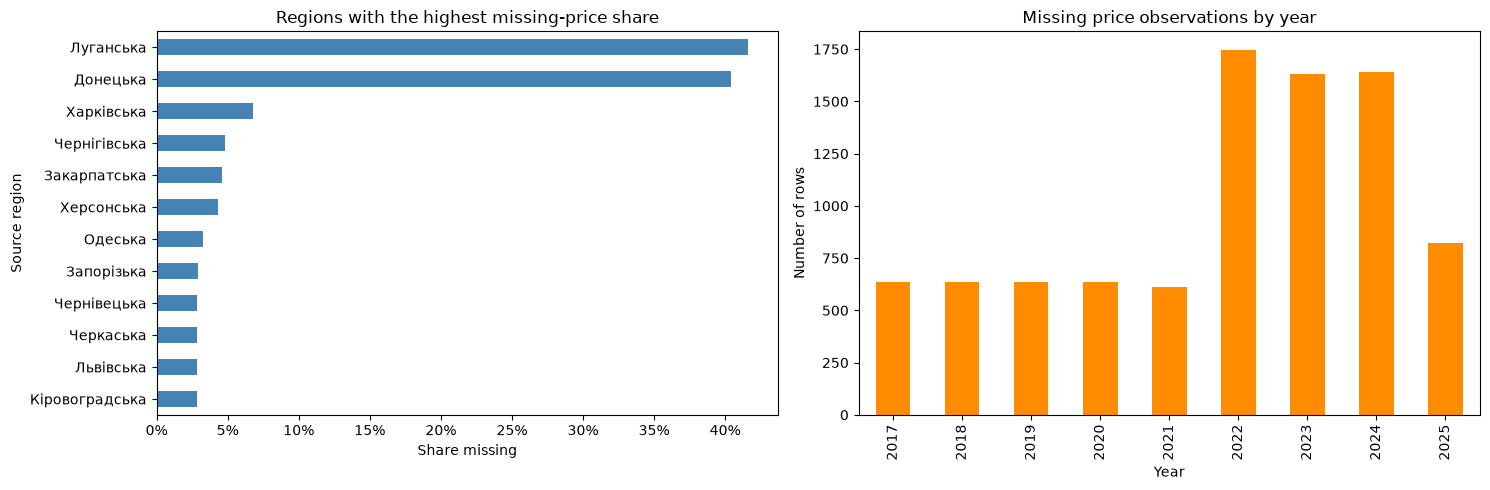

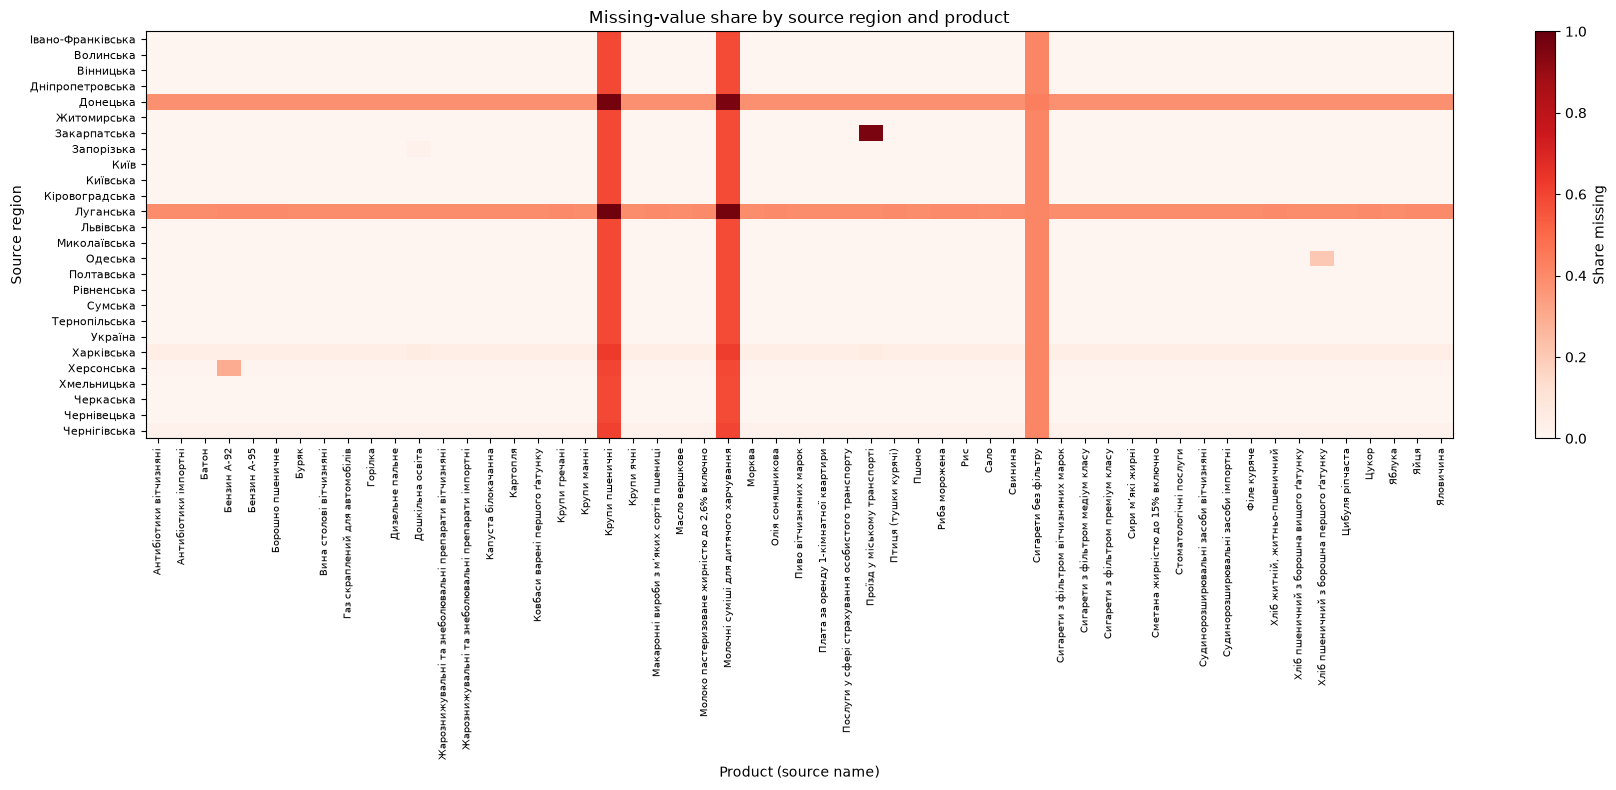

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
missing_by_region.sort_values("missing_share").tail(12).plot.barh(ax=axes[0], legend=False, color="steelblue")
axes[0].set(title="Regions with the highest missing-price share", xlabel="Share missing", ylabel="Source region")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
missing_by_year.plot.bar(ax=axes[1], color="darkorange")
axes[1].set(title="Missing price observations by year", xlabel="Year", ylabel="Number of rows")
fig.tight_layout()
plt.show()
missing_matrix = p.pivot_table(index="region", columns="good", values="is_missing", aggfunc="mean").fillna(0)
fig, ax = plt.subplots(figsize=(18, 8))
image = ax.imshow(missing_matrix, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set(title="Missing-value share by source region and product", xlabel="Product (source name)", ylabel="Source region")
ax.set_xticks(range(len(missing_matrix.columns)))
ax.set_xticklabels(missing_matrix.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(missing_matrix.index)))
ax.set_yticklabels(missing_matrix.index, fontsize=8)
fig.colorbar(image, ax=ax, label="Share missing")
fig.tight_layout()
plt.show()

## 4. Prepare the National Target Panel and Review Anomalies

The six selected national series are checked for a continuous monthly index and missing/non-positive values. We flag unusually large month-to-month log-price changes with a robust MAD score as **candidates for review**, not errors. Shocks (including 2022 onward) are retained unless source evidence shows a recording problem.

In [6]:
ukraine = p[p["region"] == UKRAINE].copy()
if ukraine.empty:
    raise ValueError("The published Ukraine aggregate was not found in the source region column")
selected = ukraine[ukraine["good"].isin(TARGET_GOODS.values())].copy()
label_by_source = {source: label for label, source in TARGET_GOODS.items()}
selected["forecast_label"] = selected["good"].map(label_by_source)
price_panel = (selected.pivot(index="date", columns="forecast_label", values="value")
    .sort_index().asfreq("MS"))
missing_targets = set(TARGET_GOODS) - set(price_panel.columns)
if missing_targets:
    raise ValueError(f"Selected series not found: {sorted(missing_targets)}")
expected_months = pd.date_range(price_panel.index.min(), price_panel.index.max(), freq="MS")
if not price_panel.index.equals(expected_months):
    raise ValueError("The selected national panel is not a continuous monthly series")
display(pd.DataFrame({"observations": price_panel.notna().sum(), "missing": price_panel.isna().sum(),
                      "minimum": price_panel.min(), "maximum": price_panel.max()}))
if price_panel.isna().any().any():
    raise ValueError("A selected target contains missing prices; resolve the policy before modeling")
if (price_panel <= 0).any().any():
    raise ValueError("A selected target contains non-positive prices; log-based analysis needs review")
log_change = np.log(price_panel).diff()
median_change = log_change.median()
mad_change = log_change.sub(median_change).abs().median().replace(0, np.nan)
robust_score = log_change.sub(median_change).mul(0.6745).div(mad_change)
flagged = robust_score.abs().gt(3.5).stack()
flagged = flagged[flagged].index
records = []
for date, label in flagged:
    previous_date = date - pd.offsets.MonthBegin(1)
    previous_price = price_panel.loc[previous_date, label]
    current_price = price_panel.loc[date, label]
    records.append({"date": date, "forecast_label": label, "price": current_price,
        "monthly_change_pct": 100 * (current_price / previous_price - 1),
        "robust_change_score": robust_score.loc[date, label]})
outliers = pd.DataFrame(records)
print("Potential extreme monthly changes (review; not automatically removed):")
display(outliers.sort_values("date") if not outliers.empty else
        pd.DataFrame(columns=["date", "forecast_label", "price", "monthly_change_pct", "robust_change_score"]))

,observations,missing,minimum,maximum
forecast_label,,,,
A-95 gasoline,102,0,21.88,56.91
Carrot,102,0,4.67,59.61
Eggs,102,0,12.06,65.05
Pasteurized milk,102,0,17.93,47.71
Potato,102,0,5.58,34.73
Sunflower oil,102,0,32.97,80.62


Potential extreme monthly changes (review; not automatically removed):


,date,forecast_label,price,monthly_change_pct,robust_change_score
0,2020-10-01,Sunflower oil,37.53,6.923077,6.345781
1,2020-11-01,Sunflower oil,40.11,6.874500,6.301749
2,2020-12-01,Sunflower oil,42.07,4.886562,4.482379
3,2021-01-01,Sunflower oil,44.04,4.682672,4.293832
4,2021-02-01,Sunflower oil,47.55,7.970027,7.289969
5,2021-03-01,Sunflower oil,52.58,10.578339,9.603012
6,2021-04-01,Sunflower oil,58.05,10.403195,9.449413
7,2021-05-01,Sunflower oil,62.57,7.786391,7.125021
8,2022-03-01,Sunflower oil,65.49,6.297679,5.777348
9,2022-05-01,A-95 gasoline,42.55,23.048005,7.086540


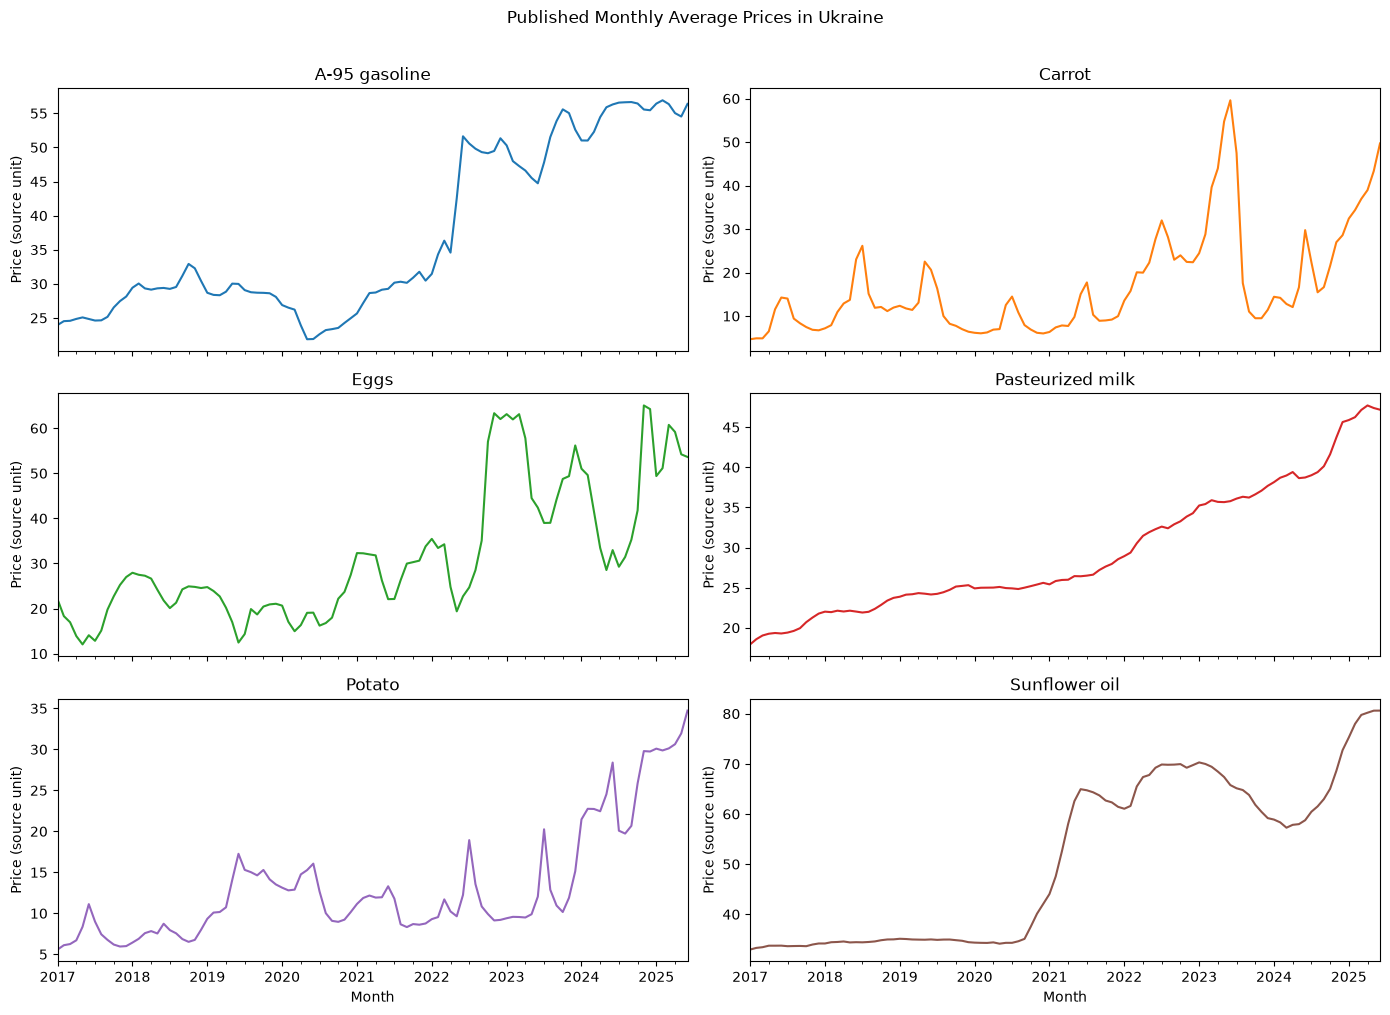

In [7]:
axes = price_panel.plot(subplots=True, layout=(3, 2), figsize=(14, 10),
                         sharex=True, legend=False)
fig = plt.gcf()
fig.suptitle("Published Monthly Average Prices in Ukraine", y=1.01)
for axis, label in zip(np.asarray(axes).ravel(), price_panel.columns):
    axis.set_title(label)
    axis.set_ylabel("Price (source unit)")
    axis.set_xlabel("Month")
fig.tight_layout()
plt.show()

## 5. EDA Findings to Carry Forward

The current processed file contains **145,860 rows**, **26 territorial categories**, and **55 products**, covering **January 2017 to June 2025** (102 monthly observations per region/product combination). There are **9,001 missing price values**: 6,349 are marked *Not available* and 2,652 *Not observed*. The total count of missing observations rises in 2022, consistent with the source notes on changing territorial coverage; this is a coverage limitation, not evidence that values should be interpolated.

For Ukraine, the baseline targets (potato, carrot, eggs, pasteurized milk, A-95 gasoline, and sunflower oil) each have 102 observations and no missing values. Wheat groats and filterless cigarettes are marked *Not observed* in many periods; infant formula also has many *Not available* observations. Keep these records in the prepared dataset, but do not use incomplete series in the baseline without an explicit missing-data strategy.

The published data is already monthly. Keep the source unit for each product and do not compare raw price levels across products with unlike units. Any anomaly flags are exploratory and do not trigger deletion.